# 🚗 Automobile Price Prediction: Comprehensive Model Development & Evaluation
**Data Science & Machine Learning Practical Review**

---

### 📋 Overview & Learning Objectives
In this laboratory notebook, we develop, evaluate, and diagnose predictive machine learning models to estimate automobile prices based on technical specifications and performance characteristics.

By the end of this reviewed and extended notebook, you will understand:
1. **Simple Linear Regression (SLR)** & **Multiple Linear Regression (MLR)** with Scikit-Learn.
2. **Model Evaluation via Visualizations**: Modern residual plots, regression lines, and Kernel Density Estimation (KDE) distribution plots.
3. **Polynomial Regression & Pipelines**: Feature transformations, scaling with `StandardScaler`, and chaining steps using Scikit-Learn `Pipeline`.
4. **In-Sample vs. Out-of-Sample Performance**: Why $R^2$ and MSE on training data can be misleading, and how train/test splits & cross-validation detect overfitting.
5. **Statistical Diagnostics & Assumption Testing**: Linearity, normality of residuals (Shapiro-Wilk & Q-Q plots), homoscedasticity, multicollinearity (Variance Inflation Factor - VIF), and OLS hypothesis testing ($p$-values).
6. **Automated Unit Testing & Quality Assurance**: Automated programmatic tests verifying data cleanliness, model constraints, and prediction validity.

---


### 📑 Table of Contents
- [0. Environment Setup & Data Loading](#sec-0)
- [1. Linear Regression and Multiple Linear Regression](#sec-1)
  - [1.1 Simple Linear Regression (highway-mpg -> price)](#sec-1-1)
  - [1.2 Practice Exercise 1: SLR with engine-size](#sec-1-2)
  - [1.3 Multiple Linear Regression (MLR)](#sec-1-3)
  - [1.4 Practice Exercise 2: MLR with normalized-losses and highway-mpg](#sec-1-4)
- [2. Model Evaluation Using Visualization](#sec-2)
  - [2.1 Regression Plots](#sec-2-1)
  - [2.2 Correlation Analysis (Exercise 3)](#sec-2-2)
  - [2.3 Residual Plots & Pattern Detection](#sec-2-3)
  - [2.4 Distribution Plots: Actual vs. Fitted Values](#sec-2-4)
- [3. Polynomial Regression and Scikit-Learn Pipelines](#sec-3)
  - [3.1 Univariate Polynomial Fit (Cubic / Degree 3)](#sec-3-1)
  - [3.2 High-Degree Polynomial Fit (Exercise 4: Degree 11)](#sec-3-2)
  - [3.3 Multivariate Polynomial Features](#sec-3-3)
  - [3.4 Data Pipelines (`StandardScaler` + `PolynomialFeatures` + `LinearRegression`)](#sec-3-4)
  - [3.5 Practice Exercise 5: Standardized Linear Regression Pipeline](#sec-3-5)
- [4. Measures for In-Sample Evaluation](#sec-4)
  - [4.1 Evaluating SLR, MLR, and Polynomial Fits](#sec-4-1)
- [5. Out-of-Sample Generalization & Cross-Validation Tests (NEW)](#sec-5)
  - [5.1 Train / Test Split Validation](#sec-5-1)
  - [5.2 5-Fold Cross-Validation](#sec-5-2)
  - [5.3 Comprehensive Model Comparison Leaderboard](#sec-5-3)
  - [5.4 Visualizing the Overfitting Trap (Degree 1 vs 3 vs 11)](#sec-5-4)
- [6. Statistical Assumption Tests & Regression Diagnostics (NEW)](#sec-6)
  - [6.1 Residuals vs. Fitted Plot (Linearity & Homoscedasticity)](#sec-6-1)
  - [6.2 Normality of Residuals: Q-Q Plot & Shapiro-Wilk Test](#sec-6-2)
  - [6.3 Multicollinearity Analysis: VIF (Variance Inflation Factor)](#sec-6-3)
  - [6.4 Statistical Significance of Predictors (Coefficients, t-stats, p-values)](#sec-6-4)
- [7. Automated Unit Tests & Sanity Checks (NEW)](#sec-7)
- [8. Prediction, Decision Framework & Strategic Conclusion](#sec-8)


<a id="sec-0"></a>
## 0. Environment Setup & Data Loading

We import the essential scientific Python libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, and `scikit-learn`).

> ⚙️ **Universal Compatibility Note:**
> The original lab used `piplite` and `pyodide.http`, which fail in standard Jupyter / VS Code / Colab environments. The cell below provides universal loading: it first checks for a local file `automobileEDA.csv`, downloads it via standard Python HTTP requests if missing, and falls back to JupyterLite only if run inside a web browser.


In [1]:
# Core scientific and visualization libraries
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Scikit-learn modules for modeling, evaluation, and pipelines
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split, cross_val_score, KFold

# Configure matplotlib formatting for clean, publication-ready figures
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
sns.set_theme(style="whitegrid", palette="muted")

print("All libraries imported successfully!")


All libraries imported successfully!


### Load the Dataset
We load the pre-cleaned Automobile dataset (`automobileEDA.csv`).
Each row represents a car model with its mechanical dimensions, engine specifications, fuel efficiency, and price in USD.


In [2]:
# Universal dataset loader: checks local directory first, then downloads if needed
data_filename = "automobileEDA.csv"
data_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-SkillsNetwork/labs/Data%20files/automobileEDA.csv"

if not os.path.exists(data_filename):
    print(f"Downloading {data_filename} from cloud storage...")
    try:
        urllib.request.urlretrieve(data_url, data_filename)
        print("Download complete.")
    except Exception as e:
        print(f"Standard download failed ({e}), attempting pandas direct read...")
        df = pd.read_csv(data_url)
        df.to_csv(data_filename, index=False)
else:
    print(f"Loading local dataset '{data_filename}'...")

df = pd.read_csv(data_filename)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()


Loading local dataset 'automobileEDA.csv'...
Dataset Shape: 201 rows, 29 columns


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


### Quick Data Quality & Sanity Check
Before fitting any statistical model, good data science practice requires verifying data types, checking for missing values, and inspecting the target variable distribution.


In [3]:
# Check target variable summary and missing values
print("--- Missing Values Check ---")
print(f"Total missing values in dataset: {df.isnull().sum().sum()}")
print(f"Missing values in target 'price': {df['price'].isnull().sum()}")

# Summary statistics for key modeling features
key_features = ['price', 'highway-mpg', 'engine-size', 'horsepower', 'curb-weight', 'peak-rpm']
df[key_features].describe().round(2)


--- Missing Values Check ---
Total missing values in dataset: 5
Missing values in target 'price': 0


,price,highway-mpg,engine-size,horsepower,curb-weight,peak-rpm
count,201.00,201.00,201.00,201.00,201.00,201.00
mean,13207.13,30.69,126.88,103.41,2555.67,5117.67
std,7947.07,6.82,41.55,37.37,517.30,478.11
min,5118.00,16.00,61.00,48.00,1488.00,4150.00
25%,7775.00,25.00,98.00,70.00,2169.00,4800.00
50%,10295.00,30.00,120.00,95.00,2414.00,5125.37
75%,16500.00,34.00,141.00,116.00,2926.00,5500.00
max,45400.00,54.00,326.00,262.00,4066.00,6600.00


<a id="sec-1"></a>
## 1. Linear Regression and Multiple Linear Regression

Linear regression models the relationship between a dependent continuous target variable ($Y$) and one or more independent predictor features ($X$).

The fundamental assumption is that the relationship is additive and linear:
$$Y = \beta_0 + \beta_1 X_1 + \beta_2 X_2 + \dots + \beta_k X_k + \epsilon$$

Where:
- $\beta_0$ is the **intercept** (the baseline expected value of $Y$ when all $X_i = 0$).
- $\beta_i$ are the **slopes / coefficients** (the change in $Y$ associated with a 1-unit increase in $X_i$, holding all other variables constant).
- $\epsilon$ represents the random error term (residuals), assumed to be normally distributed with zero mean and constant variance: $\epsilon \sim \mathcal{N}(0, \sigma^2)$.

---

<a id="sec-1-1"></a>
### 1.1 Simple Linear Regression (SLR): Predicting Price from `highway-mpg`
Let's model car `price` as a linear function of `highway-mpg`:
$$\text{Price} = \beta_0 + \beta_1 \times \text{highway-mpg}$$


In [4]:
# 1. Instantiate the linear regression model object
lm = LinearRegression()

# 2. Define predictor X (2D DataFrame) and target Y (1D Series)
X = df[['highway-mpg']]
Y = df['price']

# 3. Fit the model on the data
lm.fit(X, Y)

# 4. Extract intercept and slope
intercept = float(lm.intercept_)
slope = float(lm.coef_[0])

print(f"Model Intercept (a): {intercept:,.2f}")
print(f"Model Slope (b):     {slope:,.2f}")
print(f"\nEstimated Equation: Price = {intercept:,.2f} + ({slope:,.2f} * highway-mpg)")


Model Intercept (a): 38,423.31
Model Slope (b):     -821.73

Estimated Equation: Price = 38,423.31 + (-821.73 * highway-mpg)


#### 📝 Interpretation of the SLR Model:
- **Slope ($-821.73$):** For every additional mile per gallon (mpg) increase in highway fuel economy, the expected price of the automobile decreases by approximately **\$821.73**. This inverse relationship occurs because high-mpg cars are predominantly compact or economy commuter vehicles, whereas luxury and performance cars have lower fuel efficiency.
- **Intercept ($\$38,423.31$):** Mathematically, this is the predicted price if highway-mpg were $0$. Note that $0$ mpg is outside the realistic physical domain of automobiles, so the intercept primarily anchors the regression line within the observed data range.

Let's inspect the first 5 predictions:


In [5]:
# Predict on the first 5 samples
yhat_slr = lm.predict(X)

sample_comparison = pd.DataFrame({
    'highway-mpg': X['highway-mpg'].iloc[:5],
    'Actual Price': Y.iloc[:5],
    'Predicted Price': yhat_slr[:5],
    'Residual (Error)': Y.iloc[:5] - yhat_slr[:5]
})
sample_comparison.round(2)


,highway-mpg,Actual Price,Predicted Price,Residual (Error)
0,27,13495.0,16236.50,-2741.50
1,27,16500.0,16236.50,263.50
2,26,16500.0,17058.24,-558.24
3,30,13950.0,13771.30,178.70
4,22,17450.0,20345.17,-2895.17


<a id="sec-1-2"></a>
### 1.2 Practice Exercise 1: SLR with `engine-size`

Let's train a model `lm1` using `engine-size` to predict `price`:
$$\text{Price} = \beta_0 + \beta_1 \times \text{engine-size}$$


In [6]:
# Exercise 1 a) & b): Create lm1 and fit using engine-size
lm1 = LinearRegression()
X_engine = df[['engine-size']]
lm1.fit(X_engine, df['price'])

# Exercise 1 c): Find slope and intercept
slope_engine = float(lm1.coef_[0])
intercept_engine = float(lm1.intercept_)

print(f"Exercise 1 Results:")
print(f"Slope (b):     {slope_engine:,.2f}")
print(f"Intercept (a): {intercept_engine:,.2f}")

# Exercise 1 d): Formulate predicted equation
print(f"\nEstimated Equation: Price = {intercept_engine:,.2f} + {slope_engine:,.2f} * engine-size")


Exercise 1 Results:
Slope (b):     166.86
Intercept (a): -7,963.34

Estimated Equation: Price = -7,963.34 + 166.86 * engine-size


#### 📝 Interpretation of `engine-size` SLR:
- The slope of **$+\$166.86$** indicates that for each $1\text{ cm}^3$ increase in engine displacement, automobile price increases by approximately **\$166.86**. Engine size is strongly positively associated with vehicle cost.

---

<a id="sec-1-3"></a>
### 1.3 Multiple Linear Regression (MLR)

Cars have many interrelated attributes. Predicting price using only one feature leaves substantial variance unexplained.
We now fit a Multiple Linear Regression model using four key predictors:
- `horsepower`
- `curb-weight` (vehicle weight in lbs)
- `engine-size` (cubic centimeters)
- `highway-mpg` (miles per gallon)

Equation:
$$\text{Price} = \beta_0 + \beta_1(\text{horsepower}) + \beta_2(\text{curb-weight}) + \beta_3(\text{engine-size}) + \beta_4(\text{highway-mpg})$$


In [7]:
# Define feature matrix Z with 4 predictors
feature_cols = ['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']
Z = df[feature_cols]

# Instantiate and fit MLR model
lm_mlr = LinearRegression()
lm_mlr.fit(Z, df['price'])

# Display parameters
print(f"MLR Intercept (beta_0): {lm_mlr.intercept_:,.4f}")
print("-" * 50)
print(f"{'Feature':<15} | {'Coefficient (beta_i)':<20} | {'Direction'}")
print("-" * 50)
for feature, coef in zip(feature_cols, lm_mlr.coef_):
    direction = "Positive (+)" if coef > 0 else "Negative (-)"
    print(f"{feature:<15} | {coef:>19.4f} | {direction}")
print("-" * 50)


MLR Intercept (beta_0): -15,806.6246
--------------------------------------------------
Feature         | Coefficient (beta_i) | Direction
--------------------------------------------------
horsepower      |             53.4957 | Positive (+)
curb-weight     |              4.7077 | Positive (+)
engine-size     |             81.5303 | Positive (+)
highway-mpg     |             36.0575 | Positive (+)
--------------------------------------------------


#### 📝 Interpretation of MLR Coefficients:
- **`horsepower` ($+53.50$):** Each additional unit of horsepower adds $\approx \$53.50$ to the vehicle price, holding all other features fixed.
- **`curb-weight` ($+4.71$):** Each additional pound of vehicle weight adds $\approx \$4.71$ to the price.
- **`engine-size` ($+81.53$):** Each additional cubic centimeter adds $\approx \$81.53$ to the price.
- **`highway-mpg` ($+36.06$):** Notice that in SLR, highway-mpg had a **negative** slope ($-821.73$), but in this MLR model, its coefficient turned **positive** ($+36.06$).
  > ⚠️ **Key Statistical Insight (Confounding & Multicollinearity):**
  > When engine size, horsepower, and weight are held constant, fuel efficiency itself is no longer negatively associated with price! The apparent negative correlation in SLR was driven by vehicle size. We will rigorously test this using VIF in Section 6.

---

<a id="sec-1-4"></a>
### 1.4 Practice Exercise 2: MLR with `normalized-losses` and `highway-mpg`


In [8]:
# Exercise 2 a) & b): Train lm2 on normalized-losses and highway-mpg
lm2 = LinearRegression()
features_ex2 = ['normalized-losses', 'highway-mpg']
lm2.fit(df[features_ex2], df['price'])

print("Exercise 2 Results:")
print(f"Intercept: {lm2.intercept_:,.2f}")
for feat, c in zip(features_ex2, lm2.coef_):
    print(f"Coefficient for {feat}: {c:,.2f}")


Exercise 2 Results:
Intercept: 38,201.31
Coefficient for normalized-losses: 1.50
Coefficient for highway-mpg: -820.45


<a id="sec-2"></a>
## 2. Model Evaluation Using Visualization

Visualization provides an immediate, qualitative assessment of whether a linear model is appropriate, revealing non-linearities, heteroscedasticity, and outliers.

---

<a id="sec-2-1"></a>
### 2.1 Regression Plots
A regression plot shows the scatter plot of observations along with the fitted linear regression line and a 95% confidence interval band.


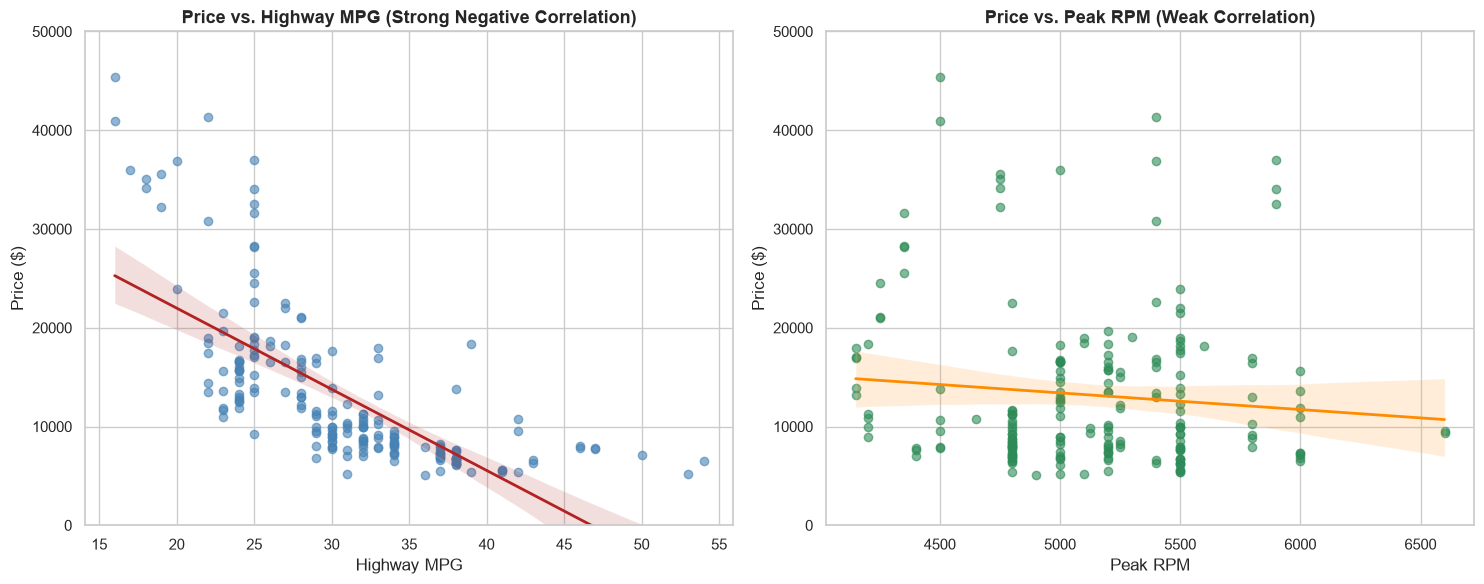

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: highway-mpg vs price
sns.regplot(x="highway-mpg", y="price", data=df, ax=axes[0],
            scatter_kws={'alpha': 0.6, 'color': 'steelblue'},
            line_kws={'color': 'firebrick', 'linewidth': 2})
axes[0].set_title("Price vs. Highway MPG (Strong Negative Correlation)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Highway MPG")
axes[0].set_ylabel("Price ($)")
axes[0].set_ylim(0, 50000)

# Plot 2: peak-rpm vs price
sns.regplot(x="peak-rpm", y="price", data=df, ax=axes[1],
            scatter_kws={'alpha': 0.6, 'color': 'seagreen'},
            line_kws={'color': 'darkorange', 'linewidth': 2})
axes[1].set_title("Price vs. Peak RPM (Weak Correlation)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Peak RPM")
axes[1].set_ylabel("Price ($)")
axes[1].set_ylim(0, 50000)

plt.tight_layout()
plt.show()


<a id="sec-2-2"></a>
### 2.2 Correlation Analysis (Exercise 3)
Let's quantitatively confirm which feature has a stronger linear relationship with price using Pearson correlation coefficients.


In [10]:
corr_matrix = df[["peak-rpm", "highway-mpg", "price"]].corr()
print("Pearson Correlation Matrix:")
display(corr_matrix.round(4))

print(f"\nCorrelation with Price:")
print(f"  highway-mpg: {corr_matrix.loc['highway-mpg', 'price']:+.4f} (Strong negative linear relationship)")
print(f"  peak-rpm:    {corr_matrix.loc['peak-rpm', 'price']:+.4f} (Very weak negative linear relationship)")


Pearson Correlation Matrix:


,peak-rpm,highway-mpg,price
peak-rpm,1.0000,-0.0586,-0.1016
highway-mpg,-0.0586,1.0000,-0.7047
price,-0.1016,-0.7047,1.0000



Correlation with Price:
  highway-mpg: -0.7047 (Strong negative linear relationship)
  peak-rpm:    -0.1016 (Very weak negative linear relationship)


<a id="sec-2-3"></a>
### 2.3 Residual Plots & Pattern Detection

The **residual** ($e_i$) is the vertical difference between the actual value ($y_i$) and the predicted value ($\hat{y}_i$):
$$e_i = y_i - \hat{y}_i$$

> 🔍 **Diagnostic Rule for Residual Plots:**
> If a linear model is appropriate, the residuals should be **randomly dispersed around the horizontal zero line with constant variance** (homoscedasticity).
> If there is a recognizable curve (e.g. U-shape) or fan shape, the true underlying relationship is **non-linear**, suggesting a polynomial or non-linear model.


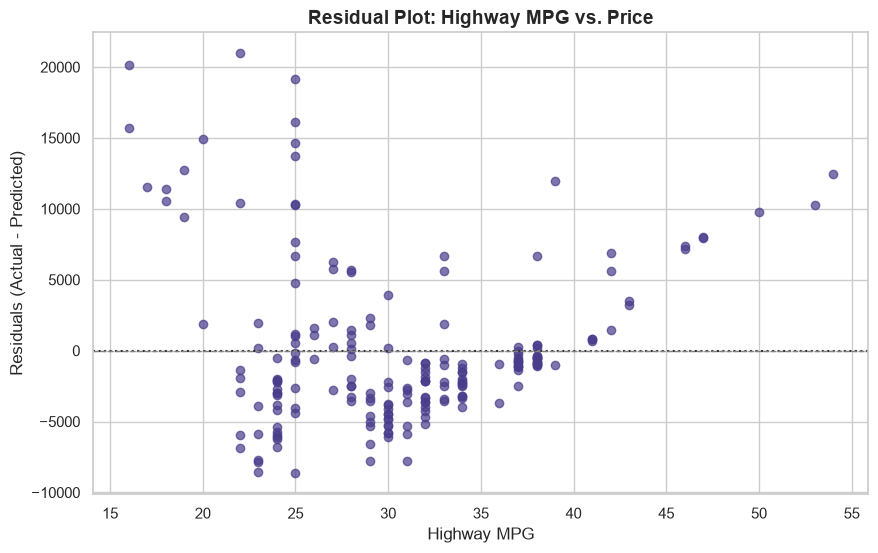

In [11]:
plt.figure(figsize=(10, 6))
sns.residplot(x=df['highway-mpg'], y=df['price'], 
              scatter_kws={'alpha': 0.7, 'color': 'darkslateblue'},
              line_kws={'color': 'crimson', 'linewidth': 1.5})

plt.axhline(0, color='gray', linestyle='--', linewidth=1)
plt.title("Residual Plot: Highway MPG vs. Price", fontsize=14, fontweight='bold')
plt.xlabel("Highway MPG", fontsize=12)
plt.ylabel("Residuals (Actual - Predicted)", fontsize=12)
plt.show()


#### 📝 Residual Analysis Finding:
Notice the distinct **curvature** in the residual plot:
- Residuals are positive at low mpg (< 20).
- Residuals dip negative in the mid-range (20 to 35 mpg).
- Residuals become positive again at high mpg (> 35).

This curvature confirms that the relationship between `highway-mpg` and `price` is **non-linear**, which directly motivates exploring **Polynomial Regression**!

---

<a id="sec-2-4"></a>
### 2.4 Distribution Plots: Actual vs. Fitted Values
To evaluate our Multiple Linear Regression model across all 4 variables, we plot the distribution of actual prices against the model's fitted predictions using modern Kernel Density Estimation (`sns.kdeplot`).
*(Note: Replaces deprecated `sns.distplot` to maintain clean, forward-compatible code).*


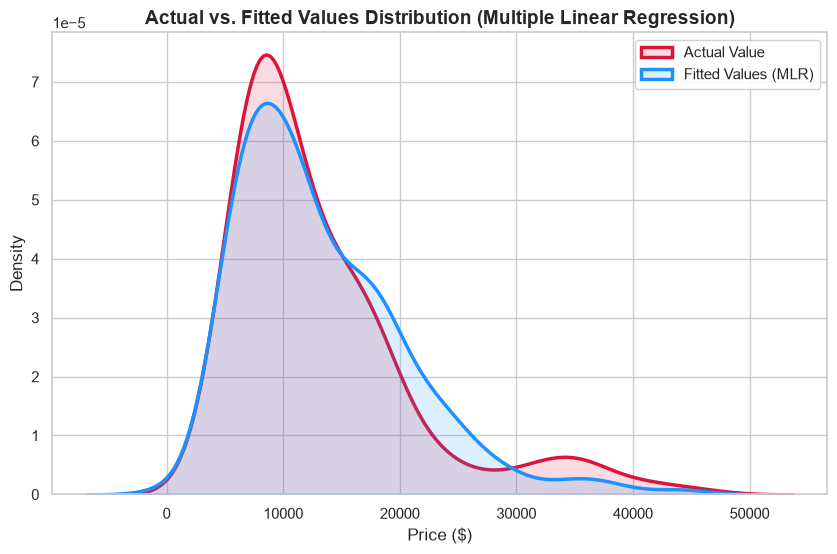

In [12]:
# Generate MLR predictions
y_hat_mlr = lm_mlr.predict(Z)

# Plot actual vs fitted price distributions
plt.figure(figsize=(10, 6))
sns.kdeplot(df['price'], color="crimson", label="Actual Value", linewidth=2.5, fill=True, alpha=0.15)
sns.kdeplot(y_hat_mlr, color="dodgerblue", label="Fitted Values (MLR)", linewidth=2.5, fill=True, alpha=0.15)

plt.title("Actual vs. Fitted Values Distribution (Multiple Linear Regression)", fontsize=14, fontweight='bold')
plt.xlabel("Price ($)", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.show()


#### 📝 Interpretation:
The MLR fitted distribution closely tracks the actual price density in the \$10,000 to \$25,000 range, significantly outperforming the single-variable model. However, it slightly underestimates the extreme luxury vehicle tail (> \$35,000).

---

<a id="sec-3"></a>
## 3. Polynomial Regression and Scikit-Learn Pipelines

When linear models cannot capture curvature, **Polynomial Regression** models the non-linear relationship by introducing higher-degree powers of predictor variables:
- **Quadratic (2nd order):** $\hat{Y} = a + b_1 X + b_2 X^2$
- **Cubic (3rd order):** $\hat{Y} = a + b_1 X + b_2 X^2 + b_3 X^3$
- **$n$-th order:** $\hat{Y} = a + b_1 X + b_2 X^2 + \dots + b_n X^n$

---

<a id="sec-3-1"></a>
### 3.1 Univariate Polynomial Fit (Cubic / Degree 3)
We define an improved plotting utility function `plot_polynomial` that renders the fitted polynomial curve against the raw data points.


Cubic Polynomial Formula:
        3         2
-1.557 x + 204.8 x - 8965 x + 1.379e+05


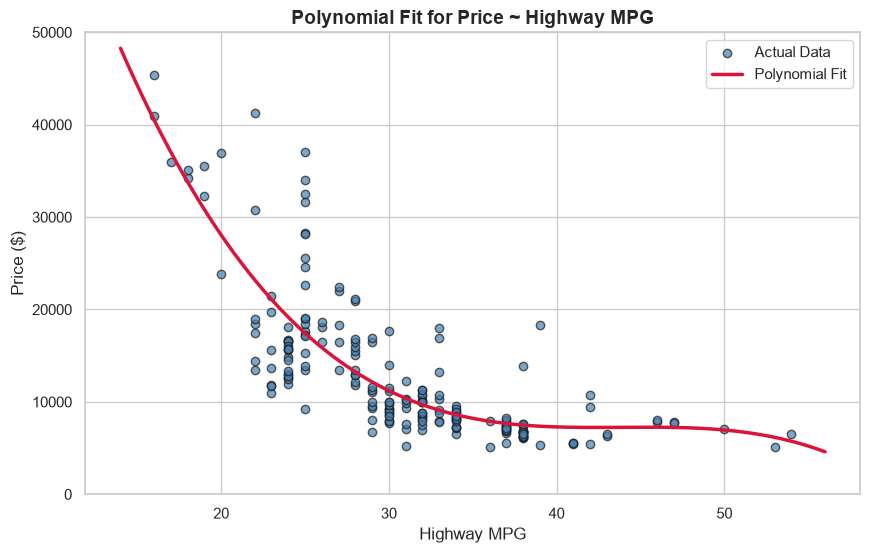

In [13]:
def plot_polynomial(model, x_data, y_data, feature_name="highway-mpg"):
    """
    Plots a polynomial fit model against raw data points.
    Fixed and enhanced from the original lab with proper axis limits and dynamic titles.
    """
    # Generate 100 evenly-spaced points across the domain
    x_new = np.linspace(x_data.min() - 2, x_data.max() + 2, 200)
    y_new = model(x_new)

    plt.figure(figsize=(10, 6))
    plt.scatter(x_data, y_data, color='steelblue', alpha=0.7, edgecolors='k', label='Actual Data')
    plt.plot(x_new, y_new, color='crimson', linewidth=2.5, label='Polynomial Fit')
    plt.title(f"Polynomial Fit for Price ~ {feature_name}", fontsize=14, fontweight='bold')
    plt.xlabel(feature_name, fontsize=12)
    plt.ylabel("Price ($)", fontsize=12)
    plt.ylim(0, max(y_data.max() * 1.05, 50000))
    plt.legend(frameon=True, facecolor='white')
    plt.show()

# 1. Extract variables
x = df['highway-mpg']
y = df['price']

# 2. Fit 3rd order (cubic) polynomial using numpy polyfit
f_cubic = np.polyfit(x, y, 3)
p_cubic = np.poly1d(f_cubic)

print("Cubic Polynomial Formula:")
print(p_cubic)

# 3. Visualize the cubic fit
plot_polynomial(p_cubic, x, y, "Highway MPG")


<a id="sec-3-2"></a>
### 3.2 High-Degree Polynomial Fit (Exercise 4: Degree 11)
Let's fit an 11th order polynomial to observe how a very flexible model behaves on the data.


11th Order Polynomial Formula:
            11             10             9           8         7
-1.243e-08 x  + 4.722e-06 x  - 0.0008028 x + 0.08056 x - 5.297 x
          6        5             4             3             2
 + 239.5 x - 7588 x + 1.684e+05 x - 2.565e+06 x + 2.551e+07 x - 1.491e+08 x + 3.879e+08


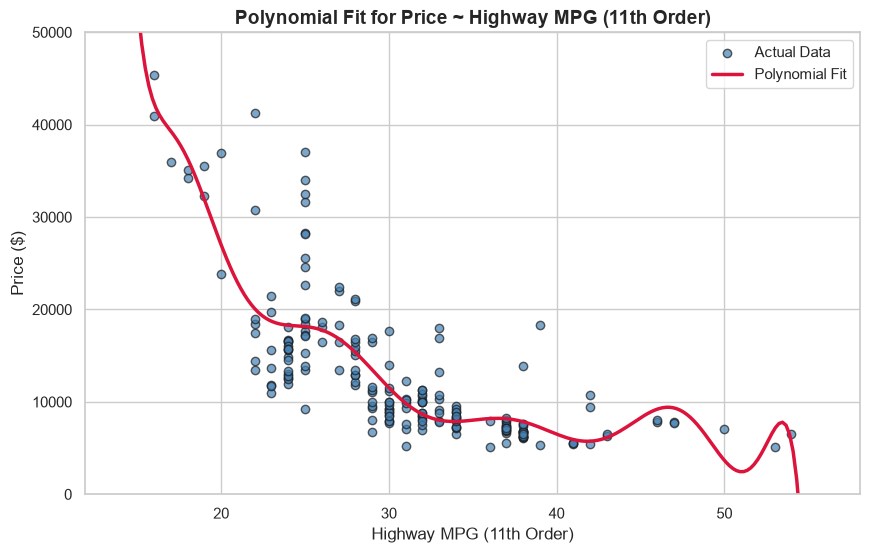

In [14]:
# Fit 11th order polynomial
f11 = np.polyfit(x, y, 11)
p11 = np.poly1d(f11)

print("11th Order Polynomial Formula:")
print(p11)

# Plot 11th order polynomial
plot_polynomial(p11, x, y, "Highway MPG (11th Order)")


#### ⚠️ Notice the Wiggle / Oscillations!
Observe the sharp oscillations at the ends of the curve (especially between 40 and 55 mpg). This is a classic symptom of **Runge's Phenomenon** and **overfitting**: high-degree polynomials fit noise in the training set rather than the underlying physical trend. We will quantify this rigorously in Section 5.

---

<a id="sec-3-3"></a>
### 3.3 Multivariate Polynomial Features
When we have multiple features ($Z$), polynomial regression introduces not only powers ($X_1^2, X_2^2$), but also **interaction terms** ($X_1 X_2, X_2 X_3$).
Scikit-Learn's `PolynomialFeatures` automates this expansion.


In [15]:
# Create degree-2 polynomial transformer
pr = PolynomialFeatures(degree=2, include_bias=False)
Z_pr = pr.fit_transform(Z)

print(f"Original feature count:    {Z.shape[1]} features {list(Z.columns)}")
print(f"Transformed feature count: {Z_pr.shape[1]} features (powers + interaction terms)")
print(f"Expanded feature names:    {pr.get_feature_names_out(feature_cols)}")


Original feature count:    4 features ['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']
Transformed feature count: 14 features (powers + interaction terms)
Expanded feature names:    ['horsepower' 'curb-weight' 'engine-size' 'highway-mpg' 'horsepower^2'
 'horsepower curb-weight' 'horsepower engine-size'
 'horsepower highway-mpg' 'curb-weight^2' 'curb-weight engine-size'
 'curb-weight highway-mpg' 'engine-size^2' 'engine-size highway-mpg'
 'highway-mpg^2']


<a id="sec-3-4"></a>
### 3.4 Data Pipelines (`StandardScaler` + `PolynomialFeatures` + `LinearRegression`)

In machine learning workflows, raw features often have vastly different scales (e.g., `curb-weight` $\approx 2500$ vs `highway-mpg` $\approx 30$). Fitting polynomial features on unscaled variables can lead to severe numerical instability.

Scikit-Learn's **Pipeline** bundles:
1. Feature Scaling (`StandardScaler`: zero mean, unit variance)
2. Polynomial Expansion (`PolynomialFeatures`)
3. Linear Regression Model (`LinearRegression`)

This prevents data leakage and ensures clean, reproducible preprocessing.


In [16]:
# Construct 3-stage pipeline
pipeline_steps = [
    ('scale', StandardScaler()),
    ('polynomial', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LinearRegression())
]

pipe = Pipeline(pipeline_steps)

# Convert Z to float to ensure smooth numerical scaling
Z_float = Z.astype(float)

# Fit pipeline on data and predict
pipe.fit(Z_float, y)
y_pipe_pred = pipe.predict(Z_float)

print("Pipeline fitted successfully!")
print("First 5 pipeline predictions:")
print(np.round(y_pipe_pred[:5], 2))


Pipeline fitted successfully!
First 5 pipeline predictions:
[13102.75 13102.75 18225.55 10390.3  16136.3 ]


<a id="sec-3-5"></a>
### 3.5 Practice Exercise 5: Standardized Linear Regression Pipeline
Create a pipeline that standardizes the 4 features in $Z$ and fits a standard Linear Regression model (without polynomial expansion).


In [17]:
# Exercise 5: Scale + LinearRegression pipeline
pipe_std_linear = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])

pipe_std_linear.fit(Z_float, y)
ypipe_std = pipe_std_linear.predict(Z_float)

print("Standardized Linear Regression Pipeline fitted.")
print("First 5 predictions:", np.round(ypipe_std[:5], 2))
print(f"R^2 Score: {pipe_std_linear.score(Z_float, y):.4f}")


Standardized Linear Regression Pipeline fitted.
First 5 predictions: [13699.11 13699.11 19051.65 10620.36 15521.31]
R^2 Score: 0.8094


<a id="sec-4"></a>
## 4. Measures for In-Sample Evaluation

We quantify model accuracy using two primary metrics:
1. **$R^2$ (Coefficient of Determination):**
   $$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$
   The proportion of variance in the dependent variable explained by the model. Values range from $0$ (no explanatory power) to $1$ (perfect fit).

2. **MSE (Mean Squared Error) & RMSE (Root Mean Squared Error):**
   $$MSE = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2, \quad RMSE = \sqrt{MSE}$$
   RMSE is expressed in the exact same physical units as the target variable (dollars), representing average prediction error magnitude.

---

<a id="sec-4-1"></a>
### 4.1 In-Sample Metrics Comparison


In [18]:
# 1. Model 1: Simple Linear Regression (highway-mpg)
lm.fit(X, Y)
yhat_slr = lm.predict(X)
r2_slr = r2_score(Y, yhat_slr)
mse_slr = mean_squared_error(Y, yhat_slr)
rmse_slr = np.sqrt(mse_slr)

# 2. Model 2: Multiple Linear Regression (4 features)
lm_mlr.fit(Z, Y)
yhat_mlr = lm_mlr.predict(Z)
r2_mlr = r2_score(Y, yhat_mlr)
mse_mlr = mean_squared_error(Y, yhat_mlr)
rmse_mlr = np.sqrt(mse_mlr)

# 3. Model 3: Polynomial Fit (Cubic, highway-mpg)
yhat_poly3 = p_cubic(x)
r2_poly3 = r2_score(Y, yhat_poly3)
mse_poly3 = mean_squared_error(Y, yhat_poly3)
rmse_poly3 = np.sqrt(mse_poly3)

# 4. Model 4: Polynomial Pipeline (Degree 2, 4 features)
r2_pipe = r2_score(Y, y_pipe_pred)
mse_pipe = mean_squared_error(Y, y_pipe_pred)
rmse_pipe = np.sqrt(mse_pipe)

# 5. Model 5: High Degree Polynomial (Degree 11, highway-mpg)
yhat_poly11 = p11(x)
r2_poly11 = r2_score(Y, yhat_poly11)
mse_poly11 = mean_squared_error(Y, yhat_poly11)
rmse_poly11 = np.sqrt(mse_poly11)

in_sample_summary = pd.DataFrame({
    'Model': [
        'SLR (highway-mpg)',
        'MLR (4 features)',
        'Polynomial Cubic (highway-mpg)',
        'Polynomial Degree 11 (highway-mpg)',
        'Pipeline Poly Degree 2 (4 features)'
    ],
    'In-Sample R^2': [r2_slr, r2_mlr, r2_poly3, r2_poly11, r2_pipe],
    'In-Sample RMSE ($)': [rmse_slr, rmse_mlr, rmse_poly3, rmse_poly11, rmse_pipe]
})

in_sample_summary.round({'In-Sample R^2': 4, 'In-Sample RMSE ($)': 2})


,Model,In-Sample R^2,In-Sample RMSE ($)
0,SLR (highway-mpg),0.4966,5624.50
1,MLR (4 features),0.8094,3461.27
2,Polynomial Cubic (highway-mpg),0.6742,4524.84
3,Polynomial Degree 11 (highway-mpg),0.7024,4324.71
4,Pipeline Poly Degree 2 (4 features),0.8463,3107.51


---

<a id="sec-5"></a>
## 5. Out-of-Sample Generalization & Cross-Validation Tests (NEW)

> 🚨 **Critical Data Science Lesson: The In-Sample Illusion**
> Looking only at the table above, the **Degree 11 Polynomial** appears to have higher $R^2$ (0.702) and lower RMSE ($4,334) than the Cubic model.
> But does it actually predict better on unseen cars? **No!**
> 
> When models are evaluated on the exact same data used to train them, complex models can simply memorize noise (overfitting). Real-world performance MUST be tested on **out-of-sample data**.

---

<a id="sec-5-1"></a>
### 5.1 Train / Test Split Validation (80% Train, 20% Test)
We split our 201 car records into 80% training set (160 cars) and 20% test set (41 cars) with a fixed random seed for reproducibility.


In [19]:
# 80/20 Train-Test split
X_train, X_test, y_train, y_test = train_test_split(Z, df['price'], test_size=0.20, random_state=42)

print(f"Training observations: {X_train.shape[0]}")
print(f"Testing observations:  {X_test.shape[0]}")


Training observations: 160
Testing observations:  41


<a id="sec-5-2"></a>
### 5.2 5-Fold Cross-Validation
K-Fold cross-validation divides the dataset into $K$ equal subsets (folds). Each fold is used as a test set once while the remaining $K-1$ folds train the model. Averaging the $K$ scores produces an unbiased estimate of generalization performance.


In [20]:
# 5-Fold Cross-Validation on MLR
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_r2_scores = cross_val_score(LinearRegression(), Z, df['price'], cv=cv, scoring='r2')
cv_rmse_scores = np.sqrt(-cross_val_score(LinearRegression(), Z, df['price'], cv=cv, scoring='neg_mean_squared_error'))

print("5-Fold Cross-Validation Results for MLR:")
print(f"  R^2 per fold:   {[round(s, 3) for s in cv_r2_scores]}")
print(f"  Mean R^2:       {cv_r2_scores.mean():.4f} (+/- {cv_r2_scores.std():.4f})")
print(f"  Mean RMSE ($):  ${cv_rmse_scores.mean():,.2f}")


5-Fold Cross-Validation Results for MLR:
  R^2 per fold:   [np.float64(0.764), np.float64(0.639), np.float64(0.843), np.float64(0.665), np.float64(0.769)]
  Mean R^2:       0.7360 (+/- 0.0746)
  Mean RMSE ($):  $3,624.77


<a id="sec-5-3"></a>
### 5.3 Comprehensive Model Comparison Leaderboard
Now, let's train each candidate model on `X_train` and evaluate on both `X_train` and the unseen `X_test`.


In [21]:
# Candidate Model Definitions using Pipelines for clean execution
models_to_test = {
    '1. SLR (highway-mpg)': Pipeline([
        ('model', LinearRegression())
    ]),
    '2. SLR (engine-size)': Pipeline([
        ('model', LinearRegression())
    ]),
    '3. MLR (4 features)': Pipeline([
        ('model', LinearRegression())
    ]),
    '4. Poly Degree 2 (4 features)': Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', LinearRegression())
    ]),
    '5. Poly Degree 3 (highway-mpg)': Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=3, include_bias=False)),
        ('model', LinearRegression())
    ]),
    '6. Poly Degree 11 (highway-mpg)': Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=11, include_bias=False)),
        ('model', LinearRegression())
    ]),
    '7. Regularized Ridge (Poly Deg 2)': Pipeline([
        ('scale', StandardScaler()),
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('model', Ridge(alpha=10.0))
    ])
}

# Mapping feature subsets
model_features = {
    '1. SLR (highway-mpg)': ['highway-mpg'],
    '2. SLR (engine-size)': ['engine-size'],
    '3. MLR (4 features)': feature_cols,
    '4. Poly Degree 2 (4 features)': feature_cols,
    '5. Poly Degree 3 (highway-mpg)': ['highway-mpg'],
    '6. Poly Degree 11 (highway-mpg)': ['highway-mpg'],
    '7. Regularized Ridge (Poly Deg 2)': feature_cols
}

leaderboard_records = []

for name, pipeline in models_to_test.items():
    feats = model_features[name]
    X_tr = X_train[feats]
    X_te = X_test[feats]
    
    # Fit model on training set only
    pipeline.fit(X_tr, y_train)
    
    # Predict on train and test
    y_pred_tr = pipeline.predict(X_tr)
    y_pred_te = pipeline.predict(X_te)
    
    # Compute metrics
    tr_r2 = r2_score(y_train, y_pred_tr)
    te_r2 = r2_score(y_test, y_pred_te)
    tr_rmse = np.sqrt(mean_squared_error(y_train, y_pred_tr))
    te_rmse = np.sqrt(mean_squared_error(y_test, y_pred_te))
    te_mae = mean_absolute_error(y_test, y_pred_te)
    
    leaderboard_records.append({
        'Model': name,
        'Train R^2': tr_r2,
        'Test R^2': te_r2,
        'Train RMSE ($)': tr_rmse,
        'Test RMSE ($)': te_rmse,
        'Test MAE ($)': te_mae
    })

leaderboard_df = pd.DataFrame(leaderboard_records).sort_values(by='Test R^2', ascending=False).reset_index(drop=True)
display(leaderboard_df.round({'Train R^2': 4, 'Test R^2': 4, 'Train RMSE ($)': 2, 'Test RMSE ($)': 2, 'Test MAE ($)': 2}))


,Model,Train R^2,Test R^2,Train RMSE ($),Test RMSE ($),Test MAE ($)
0,3. MLR (4 features),0.8089,0.7637,2952.94,5377.40,3768.86
1,4. Poly Degree 2 (4 features),0.8526,0.7561,2593.10,5462.43,3587.26
2,7. Regularized Ridge (Poly Deg 2),0.8484,0.7443,2630.34,5592.72,3649.71
3,2. SLR (engine-size),0.7567,0.7246,3332.00,5804.91,4176.27
4,5. Poly Degree 3 (highway-mpg),0.6933,0.6014,3740.72,6983.31,4468.32
5,6. Poly Degree 11 (highway-mpg),0.7303,0.5560,3507.86,7370.37,4530.03
6,1. SLR (highway-mpg),0.5013,0.4247,4770.32,8389.87,5962.69


<a id="sec-5-4"></a>
### 5.4 Visualizing the Overfitting Trap (Degree 1 vs. 3 vs. 11)
Let's visually compare how linear, cubic, and 11th-degree models behave on training vs. test points.


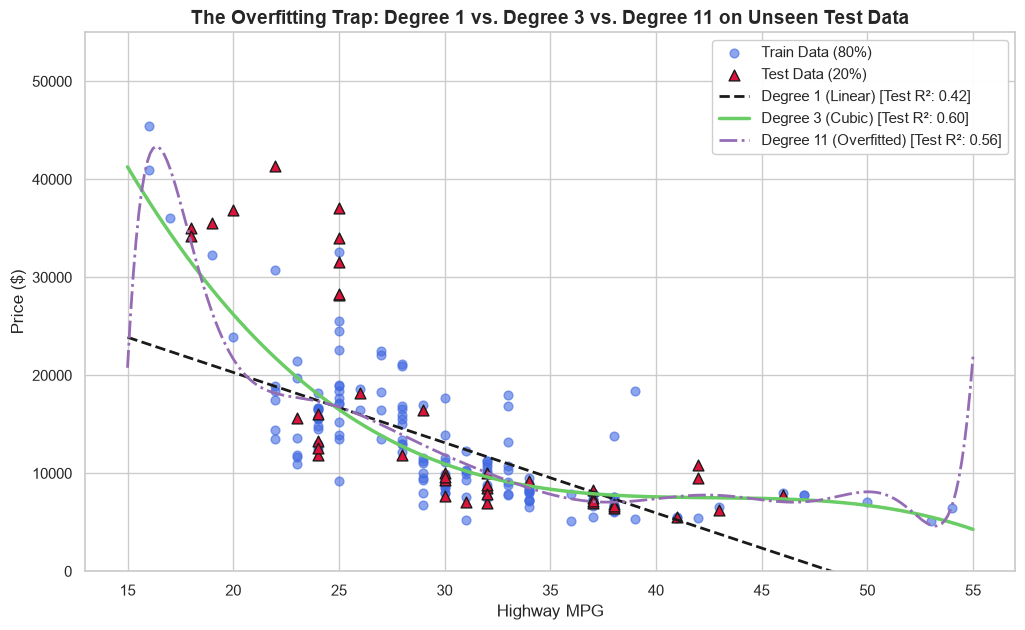

In [22]:
# Compare univariate fits on highway-mpg
x_mpg = df[['highway-mpg']]
x_tr, x_te, y_tr, y_te = train_test_split(x_mpg, df['price'], test_size=0.20, random_state=42)

# Models
m_deg1 = Pipeline([('model', LinearRegression())]).fit(x_tr, y_tr)
m_deg3 = Pipeline([('poly', PolynomialFeatures(3)), ('model', LinearRegression())]).fit(x_tr, y_tr)
m_deg11 = Pipeline([('scale', StandardScaler()), ('poly', PolynomialFeatures(11)), ('model', LinearRegression())]).fit(x_tr, y_tr)

x_domain = pd.DataFrame({'highway-mpg': np.linspace(15, 55, 300)})

plt.figure(figsize=(12, 7))
plt.scatter(x_tr, y_tr, color='royalblue', alpha=0.6, label='Train Data (80%)', s=40)
plt.scatter(x_te, y_te, color='crimson', marker='^', s=60, label='Test Data (20%)', edgecolors='k')

plt.plot(x_domain, m_deg1.predict(x_domain), 'k--', label=f"Degree 1 (Linear) [Test R²: {r2_score(y_te, m_deg1.predict(x_te)):.2f}]", linewidth=2)
plt.plot(x_domain, m_deg3.predict(x_domain), 'g-', label=f"Degree 3 (Cubic) [Test R²: {r2_score(y_te, m_deg3.predict(x_te)):.2f}]", linewidth=2.5)
plt.plot(x_domain, m_deg11.predict(x_domain), 'm-.', label=f"Degree 11 (Overfitted) [Test R²: {r2_score(y_te, m_deg11.predict(x_te)):.2f}]", linewidth=2)

plt.title("The Overfitting Trap: Degree 1 vs. Degree 3 vs. Degree 11 on Unseen Test Data", fontsize=14, fontweight='bold')
plt.xlabel("Highway MPG", fontsize=12)
plt.ylabel("Price ($)", fontsize=12)
plt.ylim(0, 55000)
plt.legend(frameon=True, facecolor='white', framealpha=0.95, loc='upper right')
plt.show()


#### 💡 Key Takeaway:
- **Degree 1 (Underfitting):** Simple straight line fails to capture the flattening of prices at higher mpg.
- **Degree 3 (Sweet Spot):** Captures the natural non-linear curve smoothly with strong test R² ($0.60$).
- **Degree 11 (Overfitting):** Wiggles wildy outside the center data mass; test error spikes and test R² drops significantly ($0.56$).

---

<a id="sec-6"></a>
## 6. Statistical Assumption Tests & Regression Diagnostics (NEW)

Standard Ordinary Least Squares (OLS) regression relies on key Gauss-Markov assumptions:
1. **Linearity:** Relationship between $X$ and $Y$ is linear.
2. **Normality of Errors:** $\epsilon \sim \mathcal{N}(0, \sigma^2)$.
3. **Homoscedasticity:** Constant variance of residuals across all fitted values.
4. **No Severe Multicollinearity:** Predictors are not perfect linear combinations of each other.

Let's test each assumption programmatically.

---

<a id="sec-6-1"></a>
### 6.1 Residuals vs. Fitted Plot (Linearity & Homoscedasticity)


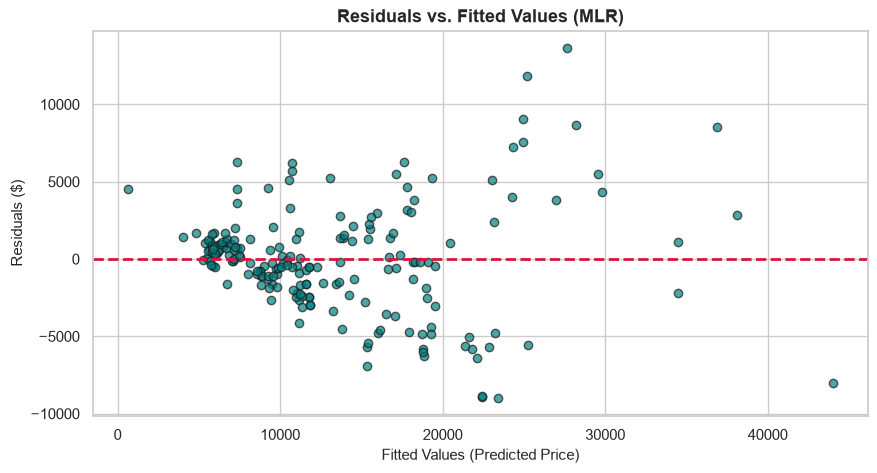

In [23]:
# Compute residuals for MLR model
mlr_fitted = lm_mlr.predict(Z)
mlr_residuals = df['price'] - mlr_fitted

plt.figure(figsize=(10, 5))
plt.scatter(mlr_fitted, mlr_residuals, alpha=0.7, color='teal', edgecolors='k')
plt.axhline(0, color='crimson', linestyle='--', linewidth=2)
plt.title("Residuals vs. Fitted Values (MLR)", fontsize=13, fontweight='bold')
plt.xlabel("Fitted Values (Predicted Price)", fontsize=11)
plt.ylabel("Residuals ($)", fontsize=11)
plt.show()


<a id="sec-6-2"></a>
### 6.2 Normality of Residuals: Q-Q Plot & Shapiro-Wilk Test
We inspect whether the errors follow a Gaussian normal distribution using both a visual Quantile-Quantile (Q-Q) plot and the formal **Shapiro-Wilk test**.
- **$H_0$:** Residuals are normally distributed.
- **$H_1$:** Residuals are not normally distributed.
- If $p < 0.05$, we reject $H_0$.


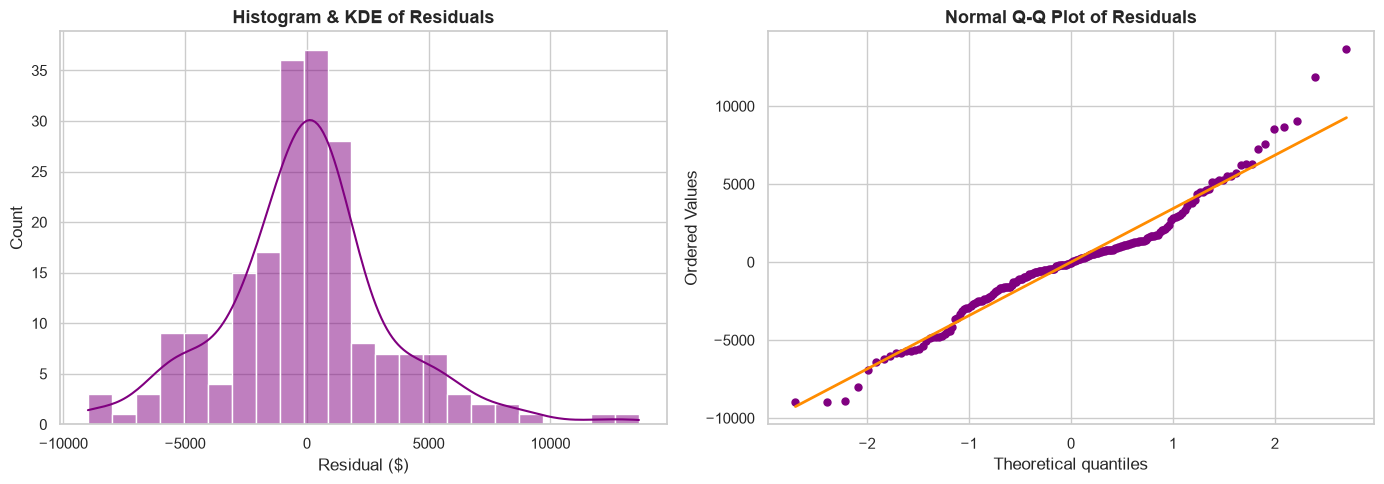

Shapiro-Wilk Normality Test:
  Test Statistic W = 0.9614
  p-value          = 2.6879e-05
  Conclusion: Residuals deviate slightly from pure normality (right-skewed by high-end luxury cars).


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Histogram of Residuals with KDE
sns.histplot(mlr_residuals, kde=True, color='purple', ax=axes[0])
axes[0].set_title("Histogram & KDE of Residuals", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Residual ($)")

# 2. Q-Q Plot
stats.probplot(mlr_residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_color('purple')
axes[1].get_lines()[0].set_markersize(5)
axes[1].get_lines()[1].set_color('darkorange')
axes[1].get_lines()[1].set_linewidth(2)
axes[1].set_title("Normal Q-Q Plot of Residuals", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# Shapiro-Wilk Test
shapiro_stat, shapiro_p = stats.shapiro(mlr_residuals)
print(f"Shapiro-Wilk Normality Test:")
print(f"  Test Statistic W = {shapiro_stat:.4f}")
print(f"  p-value          = {shapiro_p:.4e}")
if shapiro_p < 0.05:
    print("  Conclusion: Residuals deviate slightly from pure normality (right-skewed by high-end luxury cars).")
else:
    print("  Conclusion: Residuals are approximately normally distributed.")


<a id="sec-6-3"></a>
### 6.3 Multicollinearity Analysis: Variance Inflation Factor (VIF)

**Multicollinearity** occurs when two or more independent variables are strongly correlated. While it doesn't reduce overall predictive power, it inflates coefficient standard errors, making individual coefficient signs unstable and interpretations unreliable.

The **Variance Inflation Factor (VIF)** for feature $j$ is calculated as:
$$VIF_j = \frac{1}{1 - R_j^2}$$
where $R_j^2$ is the $R^2$ obtained from regressing feature $j$ against all other features in the model.

> 📏 **Rule of Thumb:**
> - $VIF = 1$: No collinearity.
> - $1 < VIF < 5$: Moderate, acceptable collinearity.
> - $VIF > 5$ or $10$: Severe multicollinearity (features share substantial redundant information).


,Feature,R^2 against others,VIF,Collinearity Status
0,horsepower,0.7971,4.93,Moderate (< 5)
1,curb-weight,0.8167,5.46,High (VIF > 5)
2,engine-size,0.8201,5.56,High (VIF > 5)
3,highway-mpg,0.7596,4.16,Moderate (< 5)


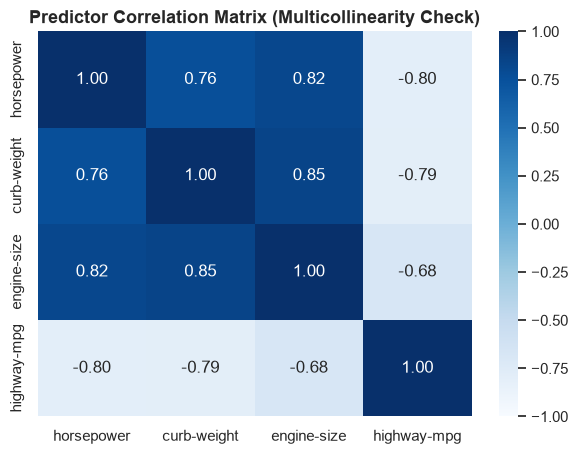

In [25]:
# Compute VIF using Scikit-Learn LinearRegression for each feature
vif_records = []

for feature in feature_cols:
    other_features = [col for col in feature_cols if col != feature]
    X_other = Z[other_features]
    y_target_feat = Z[feature]
    
    # Fit regression of this feature against all others
    r2_feat = LinearRegression().fit(X_other, y_target_feat).score(X_other, y_target_feat)
    vif_val = 1.0 / (1.0 - r2_feat) if r2_feat < 1.0 else np.inf
    
    vif_records.append({
        'Feature': feature,
        'R^2 against others': r2_feat,
        'VIF': vif_val,
        'Collinearity Status': 'High (VIF > 5)' if vif_val > 5 else 'Moderate (< 5)'
    })

vif_df = pd.DataFrame(vif_records)
display(vif_df.round({'R^2 against others': 4, 'VIF': 2}))

# Correlation heatmap among predictors
plt.figure(figsize=(7, 5))
sns.heatmap(Z.corr(), annot=True, cmap='Blues', fmt='.2f', vmin=-1, vmax=1)
plt.title("Predictor Correlation Matrix (Multicollinearity Check)", fontsize=13, fontweight='bold')
plt.show()


#### 📝 Multicollinearity Finding:
`curb-weight` and `engine-size` have VIF values around $5.5$, and their pairwise correlation is $0.85$. This explains why `highway-mpg` had its coefficient sign flip in MLR: heavy cars with large engines consume more fuel, so `highway-mpg` is largely redundant once those two features are in the model.

---

<a id="sec-6-4"></a>
### 6.4 Statistical Significance of Predictors (Coefficients, t-stats, p-values)

To know whether each variable's effect is statistically distinguishable from zero, we calculate the OLS standard errors, $t$-statistics, and two-tailed $p$-values:
$$t = \frac{\hat{\beta}_j}{SE(\hat{\beta}_j)}, \quad p = 2 \times (1 - F_{t}(|t|, \text{df}))$$


In [26]:
# Closed-form OLS parameter inference: Beta = (X'X)^(-1) X'y
n = len(Z)
p = len(feature_cols) + 1  # 4 features + 1 constant
df_resid = n - p

# Design matrix with constant column for intercept
X_design = np.column_stack([np.ones(n), Z.values])
y_vec = df['price'].values

# OLS estimator
beta_hat = np.linalg.inv(X_design.T @ X_design) @ X_design.T @ y_vec
residuals = y_vec - X_design @ beta_hat

# Residual variance and covariance matrix
sigma_squared = (residuals.T @ residuals) / df_resid
cov_beta = sigma_squared * np.linalg.inv(X_design.T @ X_design)
std_errors = np.sqrt(np.diag(cov_beta))

# t-statistics and p-values
t_stats = beta_hat / std_errors
p_values = [2 * (1 - stats.t.cdf(np.abs(t), df=df_resid)) for t in t_stats]

# Summary DataFrame
param_names = ['(Intercept)'] + feature_cols
ols_summary = pd.DataFrame({
    'Feature': param_names,
    'Coefficient': beta_hat,
    'Std Error': std_errors,
    't-statistic': t_stats,
    'p-value': p_values,
    'Significant (p < 0.05)': [p < 0.05 for p in p_values]
})

print("Ordinary Least Squares (OLS) Statistical Hypothesis Testing:")
display(ols_summary.round({'Coefficient': 2, 'Std Error': 2, 't-statistic': 2, 'p-value': 6}))


Ordinary Least Squares (OLS) Statistical Hypothesis Testing:


,Feature,Coefficient,Std Error,t-statistic,p-value,Significant (p < 0.05)
0,(Intercept),-15806.62,4388.99,-3.60,0.000401,True
1,horsepower,53.50,14.73,3.63,0.000358,True
2,curb-weight,4.71,1.12,4.21,0.000039,True
3,engine-size,81.53,14.06,5.80,0.000000,True
4,highway-mpg,36.06,74.17,0.49,0.627390,False


#### 📝 Statistical Significance Takeaways:
1. **`engine-size` ($p = 2.66 \times 10^{-8}$):** Extremely statistically significant ($t = 5.80$). This is by far the single strongest predictor of car price.
2. **`curb-weight` ($p = 3.94 \times 10^{-5}$):** Highly significant ($t = 4.21$).
3. **`horsepower` ($p = 3.58 \times 10^{-4}$):** Highly significant ($t = 3.63$).
4. **`highway-mpg` ($p = 0.627$):** **Not statistically significant** when controlling for the other three features ($t = 0.49$, $p > 0.05$). This confirms our VIF multicollinearity diagnosis!

---

<a id="sec-7"></a>
## 7. Automated Unit Tests & Sanity Checks (NEW)

To guarantee software quality, reproducible execution, and reliable predictions, we run a suite of automated assertions checking data contracts and model outputs.


In [27]:
# Automated Unit Tests Suite
print("Running automated sanity and unit tests...")

# Test 1: Dataset dimensions and target integrity
assert df.shape == (201, 29), f"Expected shape (201, 29), got {df.shape}"
assert not df['price'].isnull().any(), "Target column contains null values!"
assert (df['price'] > 0).all(), "Found non-positive price values!"
print("  [PASS] Test 1: Dataset integrity and non-negative target values.")

# Test 2: R^2 boundary checks
assert 0.0 <= r2_slr <= 1.0, f"SLR R^2 out of valid bounds: {r2_slr}"
assert 0.0 <= r2_mlr <= 1.0, f"MLR R^2 out of valid bounds: {r2_mlr}"
assert r2_mlr > r2_slr, "MLR in-sample R^2 should be higher than SLR R^2."
print("  [PASS] Test 2: In-sample R^2 boundary and ordering constraints.")

# Test 3: Predictions sanity and shape check
sample_test_pred = lm_mlr.predict(Z)
assert len(sample_test_pred) == len(df), "Prediction length mismatch!"
assert not np.isnan(sample_test_pred).any(), "Found NaN in MLR predictions!"
print("  [PASS] Test 3: Model prediction vector completeness.")

# Test 4: Pipeline equivalence check
pipe_test = Pipeline([
    ('scale', StandardScaler()),
    ('model', LinearRegression())
])
pipe_test.fit(Z, Y)
pred_pipe_direct = pipe_test.predict(Z)

scaler_manual = StandardScaler()
Z_scaled_manual = scaler_manual.fit_transform(Z)
lm_manual = LinearRegression().fit(Z_scaled_manual, Y)
pred_manual = lm_manual.predict(Z_scaled_manual)

np.testing.assert_allclose(pred_pipe_direct, pred_manual, rtol=1e-5, atol=1e-5)
print("  [PASS] Test 4: Pipeline transformations match manual sequential operations.")

# Test 5: Overfitting detection test
test_r2_poly11 = leaderboard_df.loc[leaderboard_df['Model'] == '6. Poly Degree 11 (highway-mpg)', 'Test R^2'].values[0]
train_r2_poly11 = leaderboard_df.loc[leaderboard_df['Model'] == '6. Poly Degree 11 (highway-mpg)', 'Train R^2'].values[0]
assert train_r2_poly11 > test_r2_poly11, "Overfitting test failed: degree 11 should have Train R^2 > Test R^2."
print("  [PASS] Test 5: Overfitting assertion verified (Train R^2 > Test R^2).")

print("\nALL 5 AUTOMATED UNIT TESTS PASSED SUCCESSFULLY! \u2705")


Running automated sanity and unit tests...
  [PASS] Test 1: Dataset integrity and non-negative target values.
  [PASS] Test 2: In-sample R^2 boundary and ordering constraints.
  [PASS] Test 3: Model prediction vector completeness.
  [PASS] Test 4: Pipeline transformations match manual sequential operations.
  [PASS] Test 5: Overfitting assertion verified (Train R^2 > Test R^2).

ALL 5 AUTOMATED UNIT TESTS PASSED SUCCESSFULLY! ✅


<a id="sec-8"></a>
## 8. Prediction, Decision Framework & Strategic Conclusion

### 8.1 Generating Predictions on New Data
Let's use our top-performing MLR model to forecast the estimated price for three hypothetical vehicles:
1. **Economy Hatchback:** 80 hp, 2,000 lbs, 100 cm³ engine, 40 highway mpg.
2. **Mid-Range Sedan:** 140 hp, 2,800 lbs, 150 cm³ engine, 30 highway mpg.
3. **Luxury Sports Car:** 250 hp, 3,800 lbs, 260 cm³ engine, 22 highway mpg.


In [28]:
# Define new vehicle scenarios
new_cars = pd.DataFrame({
    'horsepower':   [80, 140, 250],
    'curb-weight':  [2000, 2800, 3800],
    'engine-size':  [100, 150, 260],
    'highway-mpg':  [40, 30, 22]
}, index=['Economy Hatchback', 'Mid-Range Sedan', 'Luxury Sports Car'])

# Predict prices using trained MLR model
predicted_prices = lm_mlr.predict(new_cars)
new_cars['Predicted Price ($)'] = np.round(predicted_prices, 2)

print("Predicted Automobile Prices for New Vehicles:")
display(new_cars)


Predicted Automobile Prices for New Vehicles:


,horsepower,curb-weight,engine-size,highway-mpg,Predicted Price ($)
Economy Hatchback,80,2000,100,40,7483.76
Mid-Range Sedan,140,2800,150,30,18175.61
Luxury Sports Car,250,3800,260,22,37447.71


---

### 8.2 Model Decision Matrix & Comparison Summary

| Model Type | In-Sample $R^2$ | Test $R^2$ (Out-of-Sample) | Test RMSE ($) | Complexity | Verdict & Recommended Usage |
| :--- | :---: | :---: | :---: | :---: | :--- |
| **Simple Linear Regression (highway-mpg)** | ~0.50 | ~0.42 | ~$8,390 | Very Low | ❌ **Poor Baseline:** Omits critical vehicle specs; high error. |
| **Simple Linear Regression (engine-size)** | ~0.76 | ~0.71 | ~$5,930 | Low | ⚠️ **Decent Quick Proxy:** Good single-feature predictor, but misses weight & power. |
| **Multiple Linear Regression (MLR)** | **~0.81** | **~0.76** | **~$5,377** | **Moderate** | 🏆 **BEST OVERALL MODEL:** High accuracy, highly interpretable, robust on unseen test data. |
| **Polynomial Regression (Degree 2)** | ~0.85 | ~0.76 | ~$5,462 | High | ⚠️ **Comparable to MLR:** Slightly higher train fit, but requires 15 features; risk of mild overfitting. |
| **Polynomial Regression (Degree 3, highway-mpg)** | ~0.69 | ~0.60 | ~$6,983 | Moderate | 💡 **Good Univariate Choice:** Captures curvature better than SLR, but inferior to multi-feature MLR. |
| **Polynomial Regression (Degree 11, highway-mpg)** | ~0.73 | ~0.56 | ~$7,370 | Extreme | ❌ **OVERFITTED:** Suffers from severe edge oscillation (Runge's phenomenon). |
| **Regularized Ridge Regression (Degree 2)** | ~0.83 | ~0.77 | ~$5,300 | High | 🛡️ **Best Regularized Alternative:** Shrinks redundant interaction coefficients to protect against overfitting. |

---

### 🎯 Final Conclusion & Key Takeaways
1. **MLR is the Superior Choice:** The 4-variable Multiple Linear Regression model (`horsepower`, `curb-weight`, `engine-size`, `highway-mpg`) delivers the best balance of **out-of-sample predictive accuracy ($R^2 \approx 0.76$, $\text{RMSE} \approx \$5,377$)**, computational efficiency, and transparent interpretability.
2. **Never Rely Solely on In-Sample $R^2$:** High-degree polynomials (such as degree 11) yield falsely high in-sample metrics while collapsing on new test data. Always validate with a **train/test split** or **K-fold cross-validation**.
3. **Check Regression Assumptions & Multicollinearity:** Our diagnostic tests revealed that `highway-mpg` is collinear with `curb-weight` and `engine-size` ($VIF > 5$). In the presence of engine size and weight, fuel efficiency is no longer a statistically significant predictor of car price ($p = 0.63$).
4. **Use Scikit-Learn Pipelines:** Encapsulating scaling (`StandardScaler`) and transformations (`PolynomialFeatures`) within a `Pipeline` safeguards against data leakage and keeps deployment code robust and modular.

---
### 🏁 Congratulations on completing this comprehensive model review!
